# **AI METHODS I**
----
## Step I: Data cleaning and Exploratory Data Analysis (EDA)

### Goals

1. Load the dataset ""global_city_col_qol_index.csv"" from Kaggle directly into **pandas**.

    Steps:    
    a. Choose a python environment    
    b. Set up / Install packages with **.pip** and **import as**                
    c. Set up folders with realitve paths so they can work in any computer     
    d. Import CSV file with **.read()**      
          
2. Inspect the dataset and write a short **dataset card** (source, content, limitations).        

    Steps:    
    a. **.shape** | Number of rows and columns     
    b. **.head()** | The first rows: what the values look like                  
    c. **.info()** | Column names, data types and how many values are *not* missing |   
    d. **.describe()** | Summary statistics (mean, min, max, quartiles…) 
      
3. Detect and fix the classic **data problems**:       
           
    Steps:     
    a. Make a copy of de dataframe with **.copy()**     
    b. Tidy columns names if it's necessary     
    c. Remove all duplicated values with **.duplicated()**       
    d. Get an overview of **missing values()**  
    e. Remove irrelevant columns with **drop.()**    
    f. Fix inconsistent data types and outliers.           


4. **Feature Engineering** 
     
    Steps:     
    a. Extract **temporal features** (If necessary)  
    b. **Create** more features depending on the **relation between existing features**.              
    c. Format or transform variables to ensure they are fully model-ready   

5. **Comparing** raw and clean data sets

6. **(EDA)** Exploring the data with **descriptive statistics** and **visualizations** (matplotlib + seaborn).

    Steps:      
    a.  **Univariate**: one variable at a time    
    b.  **Bivariate**: two variables together       
    c. **Multivariate**: several variables at once      

7. Save a clean, **model-ready dataset** 

### b. Set up / Install packages with **.pip** and **import as**

In [1]:
# Set-up/ install packages.
%pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import installed packages/ libraries into environment?
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path

### c. Set up folders with realitve paths so they can work in any computer and save images as png

In [3]:
# Set-up folders --- data and figures --- relative paths to enable the notebook to work on any computer.

DATA_DIR = Path("data")      # raw and clean CSV files go here
FIG_DIR = Path("figures")    # exported plots go here

DATA_DIR.mkdir(exist_ok=True)  # create the folder if it does not exist yet
FIG_DIR.mkdir(exist_ok=True)

In [4]:
# pandas display options 
pd.set_option("display.max_columns", 50)                 # show every column, do not hide them with "..."
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# plot style 
sns.set_theme(style="whitegrid", context="notebook")  # clean background with a light grid
plt.rcParams["figure.figsize"] = (10, 5)              # default size of every figure (width, height) in inches

# Seed for anything random (sampling): the same seed always gives the same "random" result,
# so everybody in class sees exactly the same numbers.
RANDOM_STATE = 42

In [5]:
# "save_fig()" exports plots as .png 
# Creating a function to call when we need to save a figure (plot during analysis) onto the computer.

def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR.
    # dpi = dots per inch (resolution). bbox_inches="tight" trims empty white borders.
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

### d. Import CSV file with **.read()**

In [7]:
# Import csv file from data folder.
df = pd.read_csv(
    DATA_DIR / "melbourne_house_prices.csv"
)

# print info of imported csv data --- check
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")

Loaded 34,857 rows and 21 columns


# 2. Inspect de dataset

Steps:    
    a. **.shape** | Number of rows and columns     
    b. **.head()** | The first rows: what the values look like                  
    c. **.info()** | Column names, data types and how many values are *not* missing    
    d. **.describe()** | Summary statistics (mean, min, max, quartiles…) 

### Dataset card

| | |
|---|---|
| **Name** | Melbourne House Prices |
| **Source** | Kaggle, [Chaitanya Jamble](https://www.kaggle.com/datasets/chaitanyajamble/global-city-cost-of-living-and-quality-of-life-index) |
| **Origin** |Each city is anchored to the World Bank/IMF public data  |
| **Unit of observation** | ------------Two rows = one **country** of a list of 148 |
| **Size (raw)** | 34,857 Rows by 21 Columns |
| **Target for Day 2** | `quality_of_life_index` (or `qol_category`): overall quality of life score/category for each city |
| **Licence** | Check the *License* field on the Kaggle page before re-using the data in a publication |
| **Known limitations** | Contains synthetic patterns, some columns have missing values (e.g., net salary, traffic, climate), and each city appears twice across different years |

### a. **.shape** | Number of rows and columns  

In [10]:
# Use shape to see number of rows and columns
df.shape

(34857, 21)

### b. **.head()** | The first rows: what the values look like    

In [11]:
# The first 5 rows.
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,68 Studley St,2,h,NaN,SS,Jellis,3/09/2016,2.50,"3,067.00",2.00,1.00,1.00,126.00,NaN,NaN,Yarra City Council,-37.80,145.00,Northern Metropolitan,"4,019.00"
1,Abbotsford,85 Turner St,2,h,"1,480,000.00",S,Biggin,3/12/2016,2.50,"3,067.00",2.00,1.00,1.00,202.00,NaN,NaN,Yarra City Council,-37.80,145.00,Northern Metropolitan,"4,019.00"
2,Abbotsford,25 Bloomburg St,2,h,"1,035,000.00",S,Biggin,4/02/2016,2.50,"3,067.00",2.00,1.00,0.00,156.00,79.00,"1,900.00",Yarra City Council,-37.81,144.99,Northern Metropolitan,"4,019.00"
3,Abbotsford,18/659 Victoria St,3,u,NaN,VB,Rounds,4/02/2016,2.50,"3,067.00",3.00,2.00,1.00,0.00,NaN,NaN,Yarra City Council,-37.81,145.01,Northern Metropolitan,"4,019.00"
4,Abbotsford,5 Charles St,3,h,"1,465,000.00",SP,Biggin,4/03/2017,2.50,"3,067.00",3.00,2.00,0.00,134.00,150.00,"1,900.00",Yarra City Council,-37.81,144.99,Northern Metropolitan,"4,019.00"


### c. **.info()** | Column names, data types and how many values are *not* missing

In [12]:
# Column names, data types (Dtype) and number of non-missing values per column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34857 entries, 0 to 34856
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         34857 non-null  object 
 1   Address        34857 non-null  object 
 2   Rooms          34857 non-null  int64  
 3   Type           34857 non-null  object 
 4   Price          27247 non-null  float64
 5   Method         34857 non-null  object 
 6   SellerG        34857 non-null  object 
 7   Date           34857 non-null  object 
 8   Distance       34856 non-null  float64
 9   Postcode       34856 non-null  float64
 10  Bedroom2       26640 non-null  float64
 11  Bathroom       26631 non-null  float64
 12  Car            26129 non-null  float64
 13  Landsize       23047 non-null  float64
 14  BuildingArea   13742 non-null  float64
 15  YearBuilt      15551 non-null  float64
 16  CouncilArea    34854 non-null  object 
 17  Lattitude      26881 non-null  float64
 18  Longti

### d. **.describe()** | Summary statistics (mean, min, max, quartiles…)

In [13]:
# .T transposes the table (rows <-> columns) so it is easier to read with many columns
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Suburb,34857,351,Reservoir,844,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,34857,34009,5 Charles St,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rooms,"34,857.00",NaN,NaN,NaN,3.03,0.97,1.00,2.00,3.00,4.00,16.00
Type,34857,3,h,23980,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,"27,247.00",NaN,NaN,NaN,"1,050,173.34","641,467.13","85,000.00","635,000.00","870,000.00","1,295,000.00","11,200,000.00"
Method,34857,9,S,19744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SellerG,34857,388,Jellis,3359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,34857,78,28/10/2017,1119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance,"34,856.00",NaN,NaN,NaN,11.18,6.79,0.00,6.40,10.30,14.00,48.10
Postcode,"34,856.00",NaN,NaN,NaN,"3,116.06",109.02,"3,000.00","3,051.00","3,103.00","3,156.00","3,978.00"


# 3. Detect and fix the classic data problems:       
           
Steps:     
    a. Make a copy of de dataframe with **.copy()**     
    b. Tidy columns names if it's necessary     
    c. Remove all duplicated values with **.duplicated()**       
    d. Get an overview of **missing values()**  
    e. Remove irrelevant columns with **drop.()**    
    f. Fix inconsistent data types and outliers. 

### a. Make a copy of de dataframe with **.copy()**

In [14]:
# .copy() creates an independent copy: changing df_clean will NOT change df
df_clean = df.copy()

### b. Tidy columns names if it's necessary 

In [ ]:
# # Give new names to columns if they are not proper.
# new_names = {"Old_Name":"new_name",
#              "Old_Name_2":"new_name_2"}
# df_clean = df_clean.rename(columns=new_names)
# df_clean.columns.tolist()

### c. Remove all duplicated values with **.duplicated()**       


In [15]:
#Check for duplicates rows in the table
n_duplicates = df_clean.duplicated().sum()
print(f"Number of duplicate rows: {n_duplicates}")

Number of duplicate rows: 1


In [ ]:
df_clean.pop()

### d. Get an overview of **missing values()**  
   

In [16]:
#check for missing data in the table(n=missing) and percentage of missing data in the table(pct_missing)
def missing_report(data):
    n_missing = data.isnull().sum()
    pct_missing = (n_missing / len(data)) * 100
    report = pd.DataFrame({
        "n_missing": n_missing,
        "pct_missing": pct_missing  
    })
    return report.sort_values(
        "pct_missing", 
        ascending=False
    )
missing = missing_report(df_clean)
missing

,n_missing,pct_missing
BuildingArea,21115,60.58
YearBuilt,19306,55.39
Landsize,11810,33.88
Car,8728,25.04
Bathroom,8226,23.60
Bedroom2,8217,23.57
Longtitude,7976,22.88
Lattitude,7976,22.88
Price,7610,21.83
Regionname,3,0.01


Figure saved to figures\01_missing_values.png


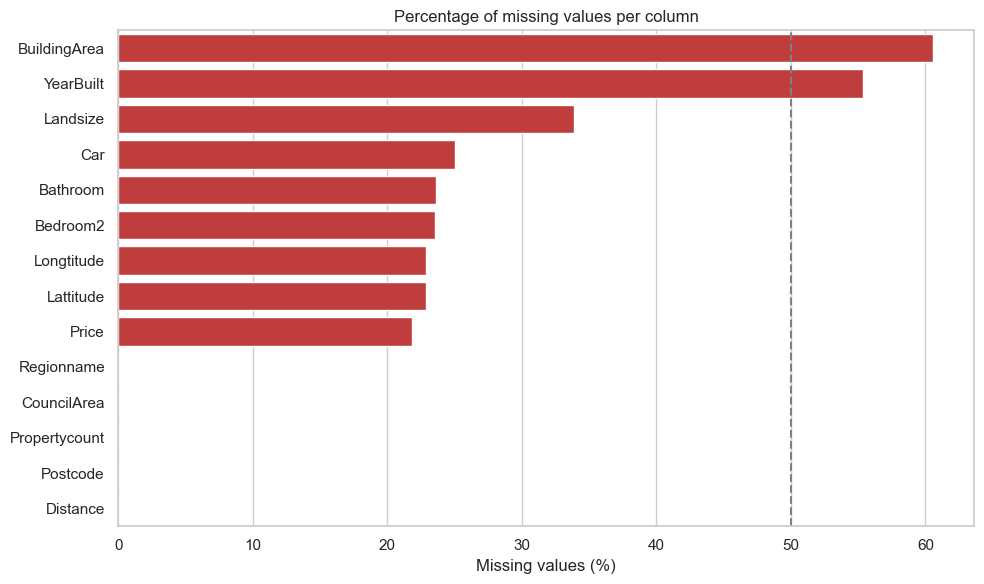

In [17]:
# Easy to understand this with a chart if there is any missing data.
# NONE in this case.

fig, ax = plt.subplots(figsize=(10, 6))

# Only plot the columns that have at least one missing value
missing_to_plot = missing[missing["pct_missing"] > 0]

sns.barplot(data=missing_to_plot, x="pct_missing", y=missing_to_plot.index, color="tab:red", ax=ax)
ax.axvline(50, color="grey", linestyle="--")   # reference line at 50%
ax.set_title("Percentage of missing values per column")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
plt.tight_layout()
save_fig("01_missing_values")
plt.show()

# Can decide what columns to drop based on this analysis.

Check the code below and for columns adn rows to remove. 

In [27]:
print((df_clean)["Price"].isna().sum())
df_clean = df_clean.dropna(subset=["price"])
print((df_clean)["Price"].isna().sum())


7610


KeyError: ['price']

In [ ]:
# Check missing values before imputation
print("--- Missing values before imputation ---")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# List of columns with missing values to impute
cols_to_impute = [
    ''
]

# Fill missing values with the median of each column
for col in cols_to_impute:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

# Verify that no missing values remain in the dataset
print("\n--- Missing values after imputation ---")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])